**PNV3421 - Exercício 1 de ARIMA**


In [ ]:
# ===============================
# 1. IMPORTAÇÃO E CARREGAMENTO
# ===============================
# Desligar alguns warnings
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import ValueWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller

warnings.simplefilter("ignore", ValueWarning)
warnings.filterwarnings("ignore")  # novo

# Carregar dataset
df = pd.read_csv("Exercício1.txt", delimiter=" ", decimal=",")
df.reset_index(drop=True, inplace=True)
df.head()

Mounted at /content/drive


,Yt
0,-0.23
1,0.63
2,0.48
3,-0.83
4,-0.03


In [ ]:
# ===============================
# 2. TESTE DE ESTACIONARIDADE
# ===============================
result = adfuller(df)
print(f"ADF: {result[0]}")
print(f"p-value: {result[1]}")

plt.rcParams.update({"figure.figsize": (10, 7), "figure.dpi": 120})

ADF: -9.813093569687899
p-value: 5.589199949525307e-17


Conclusão: série original já é estacionária


In [ ]:
# ===============================
# 3. AJUSTE DE MODELOS ARIMA
# ===============================
print("\n==== ARIMA(1,1,0) ====\n")
model = ARIMA(df, order=(1, 1, 0))
model_fit = model.fit()
print(model_fit.summary())


==== ARIMA(1,1,0) ====

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   90
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -152.828
Date:                Fri, 28 Nov 2025   AIC                            309.656
Time:                        15:58:04   BIC                            314.633
Sample:                             0   HQIC                           311.662
                                 - 90                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6962      0.084     -8.277      0.000      -0.861      -0.531
sigma2         1.8022      0.294      6.126      0.000       1.226       2.379
Ljung-Box (L1) (Q):        

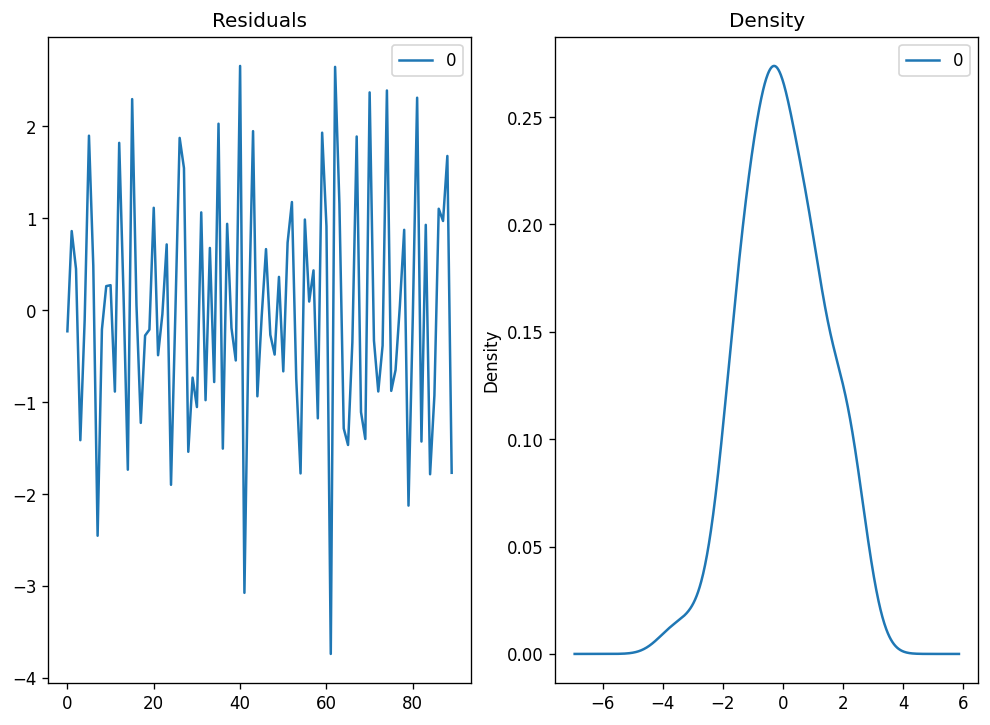

In [ ]:
# ===============================
# 4. RESÍDUOS
# ===============================
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1, 2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind="kde", title="Density", ax=ax[1])
plt.show()

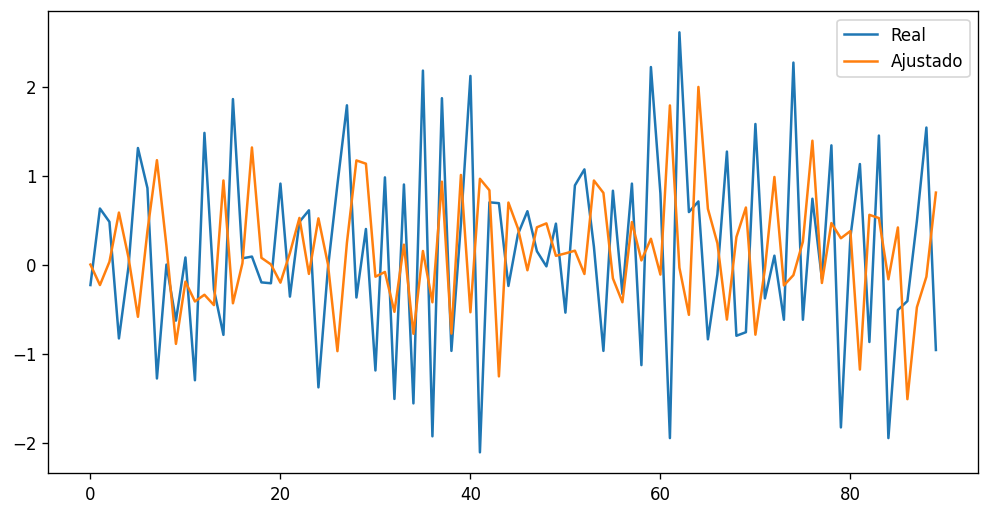

In [ ]:
# ===============================
# 5. AJUSTE DENTRO DA AMOSTRA
# ===============================
pred = model_fit.get_prediction()
pred_ci = pred.conf_int()

plt.figure(figsize=(10, 5))
plt.plot(df.index, df, label="Real")
plt.plot(pred.predicted_mean.index, pred.predicted_mean, label="Ajustado")
plt.legend()
plt.show()

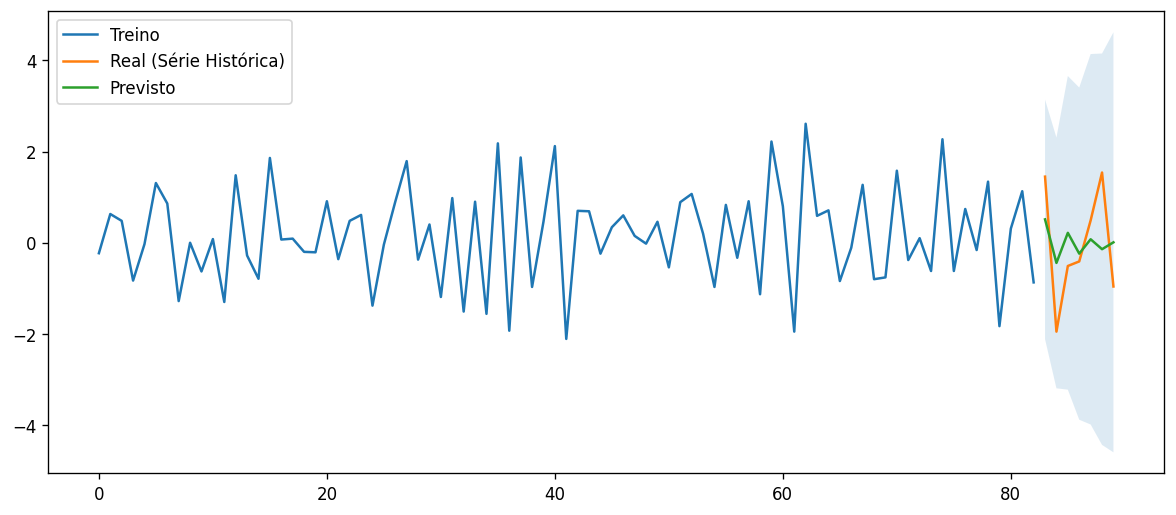

In [ ]:
# ===============================
# 6. TREINO / TESTE
# ===============================
train = df[: n - 7]
test = df[n - 7 :]

# ARIMA 1,1,0 para previsão no TESTE
model = ARIMA(train, order=(1, 1, 0))
fitted = model.fit()

pred = fitted.get_forecast(steps=len(test))
fc = pred.predicted_mean
conf = pred.conf_int()

fc_series = pd.Series(fc, index=test.index)
lower = pd.Series(conf.iloc[:, 0], index=test.index)
upper = pd.Series(conf.iloc[:, 1], index=test.index)

plt.figure(figsize=(12, 5))
plt.plot(train, label="Treino")
plt.plot(test, label="Real (Série Histórica)")
plt.plot(fc_series, label="Previsto")
plt.fill_between(test.index, lower, upper, alpha=0.15)
plt.legend()
plt.show()

In [8]:
print(len(train))
print(len(test))

83
7


In [9]:
# ===============================
# 7. IDENTIFICANDO MODELO VÁLIDO PELO BOX JENKINS
# ===============================

P = range(0, 4)
D = range(0, 4)
Q = range(0, 4)

melhor_aic = float("inf")
melhor_bic = float("inf")
melhor_ordem_aic = None
melhor_ordem_bic = None
melhor_modelo_aic = None
melhor_modelo_bic = None

for p in P:
    for d in D:
        for q in Q:
            try:
                modelo = ARIMA(train, order=(p, d, q)).fit()
                aic = modelo.aic
                bic = modelo.bic
                if aic < melhor_aic:
                    melhor_aic = aic
                    melhor_ordem_aic = (p, d, q)
                    melhor_modelo_aic = modelo
                if bic < melhor_bic:
                    melhor_bic = bic
                    melhor_ordem_bic = (p, d, q)
                    melhor_modelo_bic = modelo
            except:
                pass

print("Melhor modelo por AIC:", melhor_ordem_aic, " | AIC:", melhor_aic)
print("Melhor modelo por BIC:", melhor_ordem_bic, " | BIC:", melhor_bic)

if melhor_ordem_aic != melhor_ordem_bic:
    print("Aviso: o modelo ótimo pelo AIC não coincide com o ótimo pelo BIC.")
    print("\nResumo do modelo escolhido pelo AIC:")
    print(melhor_modelo_aic.summary())
    print("\nResumo do modelo escolhido pelo BIC:")
    print(melhor_modelo_bic.summary())
else:
    print("O melhor modelo é o mesmo para AIC e BIC.")
    print("\nResumo do melhor modelo:")
    print(melhor_modelo_bic.summary())

Melhor modelo por AIC: (0, 0, 1)  | AIC: 221.15918743340714
Melhor modelo por BIC: (0, 0, 1)  | BIC: 228.41570925679693
O melhor modelo é o mesmo para AIC e BIC.

Resumo do melhor modelo:
                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   83
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -107.580
Date:                Fri, 28 Nov 2025   AIC                            221.159
Time:                        15:58:21   BIC                            228.416
Sample:                             0   HQIC                           224.074
                                 - 83                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1704 


==== ARIMA("ótimo") ====

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   83
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -107.580
Date:                Fri, 28 Nov 2025   AIC                            221.159
Time:                        15:58:21   BIC                            228.416
Sample:                             0   HQIC                           224.074
                                 - 83                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1704      0.038      4.514      0.000       0.096       0.244
ma.L1         -0.6140      0.084     -7.342      0.000      -0.778      -0.450
sigma2         0.7778    

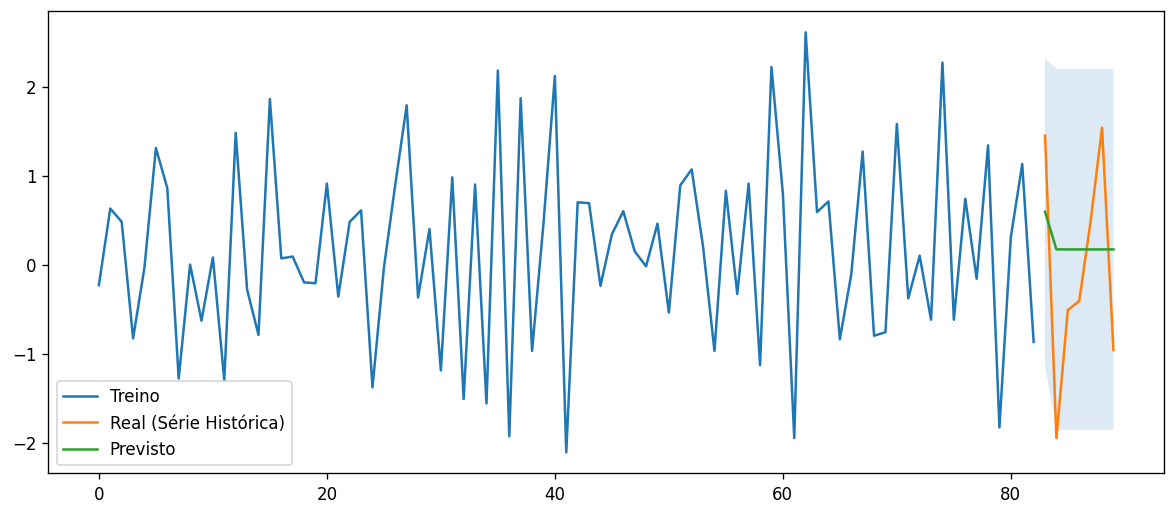

In [ ]:
# ===============================
# 8. PLOTANDO ARIMA ÓTIMO
# ===============================
print('\n==== ARIMA("ótimo") ====\n')
model = ARIMA(train, order=melhor_ordem_aic)
fitted = model.fit()
print(fitted.summary())

pred = fitted.get_forecast(steps=len(test))
fc = pred.predicted_mean
conf = pred.conf_int()

fc_series = pd.Series(fc, index=test.index)
lower = pd.Series(conf.iloc[:, 0], index=test.index)
upper = pd.Series(conf.iloc[:, 1], index=test.index)

plt.figure(figsize=(12, 5))
plt.plot(train, label="Treino")
plt.plot(test, label="Real (Série Histórica)")
plt.plot(fc_series, label="Previsto")
plt.fill_between(test.index, lower, upper, alpha=0.15)
plt.legend()
plt.show()

In [ ]:
# ===============================
# 9. MÉTRICAS
# ===============================
def forecast_accuracy(forecast, actual):
    forecast = np.asarray(forecast)
    actual = np.asarray(actual)

    mape = np.mean(np.abs(forecast - actual) / np.abs(actual))
    me = np.mean(forecast - actual)
    mae = np.mean(np.abs(forecast - actual))
    mpe = np.mean((forecast - actual) / actual)
    rmse = np.sqrt(np.mean((forecast - actual) ** 2))
    corr = np.corrcoef(forecast, actual)[0, 1]

    mins = np.minimum(forecast, actual)
    maxs = np.maximum(forecast, actual)
    minmax = 1 - np.mean(mins / maxs)

    erro = forecast - actual
    acf1 = acf(erro, fft=False)[1]

    return {
        "mape": mape,
        "me": me,
        "mae": mae,
        "mpe": mpe,
        "rmse": rmse,
        "corr": corr,
        "minmax": minmax,
        "acf1": acf1,
    }


print("\nMÉTRICAS:")
print(
    forecast_accuracy(
        fc_series.values,
        test.values.reshape(
            -1,
        ),
    )
)


MÉTRICAS:
{'mape': np.float64(1.0210226692035897), 'me': np.float64(0.280719643604567), 'mae': np.float64(1.008257457892865), 'mpe': np.float64(-1.0210226692035897), 'rmse': np.float64(1.1517694414780038), 'corr': np.float64(0.5162601284777504), 'minmax': np.float64(4.087897527510837), 'acf1': np.float64(-0.20946051179969563)}


In [ ]:
# ===============================
# 10. AUTO-ARIMA
# ===============================

!pip install pmdarima
import pmdarima as pm

model = pm.auto_arima(
    df,  # note que aqui fiz com o df todo
    # seasonal=True,
    # m=12,                   # se mensal
    stepwise=True,  # rápido e estável
    trace=True,  # mostra a busca (estilo Box-Jenkins)
    error_action="ignore",
    suppress_warnings=True,
)

print(model.summary())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 11.0 MB/s eta 0:00:00
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=249.999, Time=0.35 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=272.873, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=249.389, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=244.816, Time=0.04 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=272.537, Time=0.01 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=246.085, Time=0.06 sec
 ARIMA(0,0,2)(0,0,0)[0] intercept   : AIC=246.132, Time=0.05 sec
 ARIMA(1,0,2)(0,0,0)[0] intercept   : AIC=248.027, Time=0.11 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=252.475, Time=0.02 sec

Best model:  ARIMA(0,0,1)(0,0,0)[0] intercept
Total fit time: 0.720 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   90
Model:               SARIMAX(0, 0, 1)   Log Likelihood  

Conclusão: melhor previsão com média móvel de ordem 1 (q=1)



==== ARIMA("ótimo") ====

                               SARIMAX Results                                
Dep. Variable:                     Yt   No. Observations:                   90
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -119.408
Date:                Fri, 28 Nov 2025   AIC                            244.816
Time:                        15:58:30   BIC                            252.316
Sample:                             0   HQIC                           247.841
                                 - 90                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1512      0.041      3.732      0.000       0.072       0.231
ma.L1         -0.5816      0.082     -7.064      0.000      -0.743      -0.420
sigma2         0.8278    

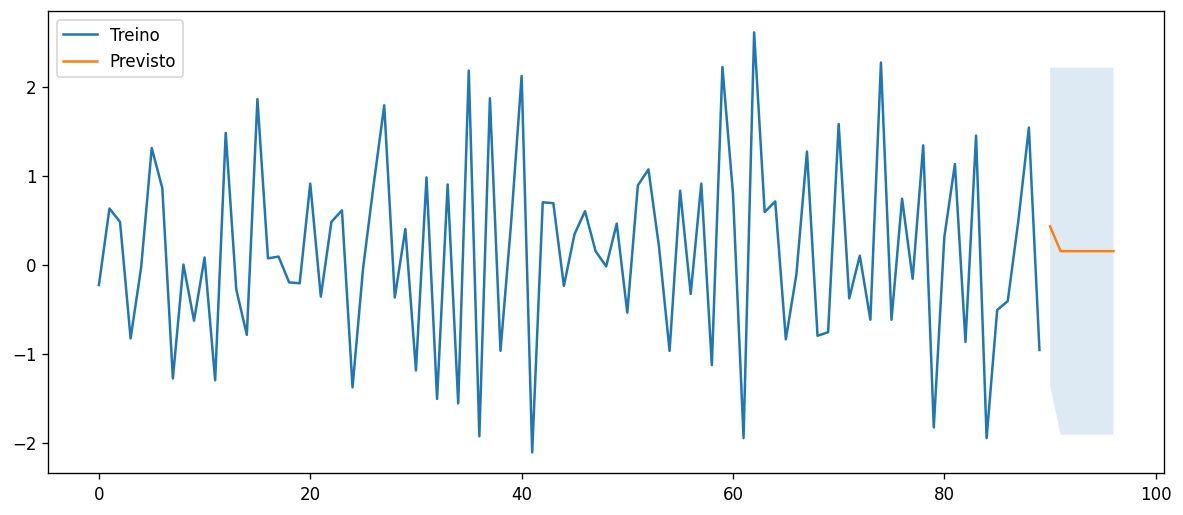

In [ ]:
# ===============================
# 11. PLOTANDO ARIMA ÓTIMO NAS PRÓXIMAS 7 MEDIÇÕES (PREVISÂO PARA AS PRÓXIMAS 7 MEDIÇÕES)
# ===============================
print('\n==== ARIMA("ótimo") ====\n')
model = ARIMA(
    df, order=melhor_ordem_aic
)  # acabamos de checar com o auto, note que train->df
fitted = model.fit()
print(fitted.summary())

pred = fitted.get_forecast(
    steps=len(test)
)  # convenientemente setei o test do mesmo tamanho
fc = pred.predicted_mean
conf = pred.conf_int()

fc_series = pd.Series(fc, index=range(n, n + 7))
lower = pd.Series(conf.iloc[:, 0], index=range(n, n + 7))
upper = pd.Series(conf.iloc[:, 1], index=range(n, n + 7))

plt.figure(figsize=(12, 5))
plt.plot(df, label="Treino")
plt.plot(fc_series, label="Previsto")
plt.fill_between(range(n, n + 7), lower, upper, alpha=0.15)
plt.legend()
plt.show()